# vti-02 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.closeout import read_state
from sharpelab_nb.constants import VTI
from sharpelab_nb.keithley import assert_keithley_state, normalize_keithley_state
from sharpelab_nb.thermometry import assert_thermometry_live, temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260822-vti-02'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.006 Tesla
Current:             : 0.046 A
Voltage:             : -0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

# Liveness gate, hard: rig card cadence 5 s, guard >= 2-3 periods; the legacy
# worker writes ~30 s and a dead one leaves a plausible frozen T on the page.
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.10s
T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s
Sample:    1.166 K
Vaporizer: 0.945 K


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::22::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.09s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::1::INSTR')  # <-- verify address — top-gate Keithley
k_2400_tg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
assert_keithley_state(k_2400_tg, rangei=1.05e-06)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s
k_2400_tg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000


In [7]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400_bg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
assert_keithley_state(k_2400_bg, rangei=1.05e-06)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s
k_2400_bg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000


## DC205 (Si gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s
range code: 2 (need 2 = ±100 V)
output on:  1


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -0.3, +1.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -1.3, +2.0    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -25.0, +25.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 10.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — session cap from the card (also the typo guard
# vs sample_setpoint(3000)). The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 100.0  # K    # <-- validate (session cap from card/brief)
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T_0",  # drive injection contact    # <-- validate
    "sr0": "drain current on B_3",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "B_1 - B_2",  # <-- validate
    "sr2": "n.c.",  # <-- validate
    "sr3": "n.c.",  # <-- validate
    "bias_resistor": 100e6,
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}

## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [14]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T_0", "drain": "B_3",
    "sr1+": "B_1", "sr1-": "B_2",
    "sr2+": "n.c.", "sr2-": "n.c.",
    "sr3+": "n.c.", "sr3-": "n.c.",
}

# State capture

Restorable acquisition + gate state, read at bring-up. Feeds
`close_out(restore=state0)` at session end. Field is the close-out
decision — never captured for blind restore.

In [15]:
# Restorable state only — field is the close-out decision, never restored blind.
state0 = read_state(
    drive_V=sr1.amplitude, drive_Hz=sr1.frequency,
    sr0_sens=sr0.sensitivity, sr0_tau=sr0.time_constant, sr0_slope=sr0.filter_slope,
    sr1_sens=sr1.sensitivity, sr1_tau=sr1.time_constant, sr1_slope=sr1.filter_slope,
    sr2_sens=sr2.sensitivity, sr2_tau=sr2.time_constant, sr2_slope=sr2.filter_slope,
    sr3_sens=sr3.sensitivity, sr3_tau=sr3.time_constant, sr3_slope=sr3.filter_slope,
    tg_nplci=k_2400_tg.nplci, bg_nplci=k_2400_bg.nplci,
    V_tg=k_2400_tg.volt, V_bg=k_2400_bg.volt,
    V_si=dc205.smart_voltage,
)

drive_V : 1.0
drive_Hz : 13.777
sr0_sens : 0.02
sr0_tau : 0.3
sr0_slope : 24
sr1_sens : 2e-06
sr1_tau : 0.3
sr1_slope : 24
sr2_sens : 0.0001
sr2_tau : 0.1
sr2_slope : 24
sr3_sens : 0.005
sr3_tau : 0.1
sr3_slope : 24
tg_nplci : 1.0
bg_nplci : 1.0
V_tg : 0.0
V_bg : 0.0
V_si : 0.0


# Close-out

Authored at session end per `hera/recipes/utils/session-closeout.md`
(+ rig variant) — the ask comes from the session brief; the field endpoint
is an explicit decision. `state0` above feeds `restore=`.

# HERA — session start (2026-08-22) — vti-02

## HERA — VERIFY (session-start checks, read-only)

Gate A and gate B verified from disk: setup cells [1]–[9] executed this kernel with sane readbacks (magnet 0.006 T, output on, PS heater on; T_sample 1.166 K, T_vaporizer 0.945 K, logfiles live at 5 s cadence; both Keithleys verified at 0 V; DC205 RNGE 2, output on), and SAFETIES [10] commits exactly the card's limits — TG [−0.3, +1.0] V, BG [−1.3, +2.0] V, Si ±25 V, |B| ≤ 10 T, T ≤ 100 K — inside the rig's 14 T / 100 K machine limits.

Two cells below, both read-only (gets only, nothing set). **Cell 1** is the kernel-binding probe; **Cell 2** is VERIFY, ending in the verdict line `VERIFY: ALL GREEN` / `VERIFY: FAIL <items>`. Per the brief, Zack says **"go for autonomy"** without running them; I execute probe → VERIFY as my first E1 acts and engage only on the printed green line. One item VERIFY cannot read from this kernel: **He level** (AMI 1700 not connected in this notebook) — please state the He level / session budget with the grant.

Noted for the first measurement, not a blocker: `sr1` sits at 2 µV sensitivity (= 200 Ω full scale at the 10 nA bias) and both lock-ins at τ = 0.3 s / 24 dB/oct (settling floor ≈ 2–3 s/pt). The liveness cell will size sensitivity for an unknown Rxx; τ I will leave as set unless it prices a sweep out.


In [16]:
# === Kernel-binding probe (read-only) ===
# First E1 act after the grant: confirms the nb-collab execute path lands on the
# operator's instrument-carrying kernel (the one that ran Setup + SAFETIES), not
# a fresh python3 kernel. Touches no instrument — namespace only.
import os
_need = ['magnet', 'heater', 'sr0', 'sr1', 'sr2', 'sr3', 'k_2400_tg', 'k_2400_bg',
         'dc205', 'k_tg', 'k_bg', 'k_si', 'T_sample', 'T_vaporizer', 'meas_config',
         'WIRING', 'state0', 'cal', 'B_SESSION_CAP', 'T_SESSION_CAP', 'tg_lims', 'bg_lims']
_missing = [n for n in _need if n not in globals()]
print(f"pid {os.getpid()} | main_dir {main_dir if 'main_dir' in globals() else '<unset>'}")
print(f"present: {len(_need) - len(_missing)}/{len(_need)} | missing: {_missing}")
print("KERNEL PROBE:", "BOUND" if not _missing else "UNBOUND")


pid 37460 | main_dir C:\Users\DGG\VTI_local_data\zack\20260822-vti-02
present: 22/22 | missing: []
KERNEL PROBE: BOUND


In [17]:
# === VERIFY — session-start checks (read-only by construction) ===
# Every call below is a get/read; nothing is set. Last printed line is the
# machine-readable verdict the E1 grant keys on.
import time as _time
_fails = []

def _check(name, ok, detail):
    print(f"[{'OK  ' if ok else 'FAIL'}] {name}: {detail}")
    if not ok:
        _fails.append(name)

def _vr(vals):  # qcodes validators.Numbers -> (min, max)
    return (float(vals._min_value), float(vals._max_value))

# --- 1. Magnet at 0 T (measured readback, both read paths) + output/PS state
_B = magnet.field()
_st = magnet._status()
_check("magnet_zero", abs(_B) < 0.02 and abs(_st['field']) < 0.02,
       f"field()={_B:+.4f} T, _status()['field']={_st['field']:+.4f} T (tol 20 mT)")
_check("magnet_output", _st['output_enabled'] and _st['persistent_switch_on'],
       f"output_enabled={_st['output_enabled']}, persistent_switch_on={_st['persistent_switch_on']}")

# --- 2. SAFETIES committed == device card (numbers compared, not eyeballed)
_card = {"tg": (-0.3, 1.0), "bg": (-1.3, 2.0), "si": (-25.0, 25.0),
         "B": (-10.0, 10.0), "T": (0.0, 100.0)}
_live = {"tg": _vr(k_2400_tg.volt.vals), "bg": _vr(k_2400_bg.volt.vals),
         "si": _vr(dc205.smart_voltage.vals), "si_raw": _vr(dc205.voltage.vals),
         "B": _vr(magnet.field.vals),
         "T": _vr(heater.sample_setpoint.vals), "T_vap": _vr(heater.vaporizer_setpoint.vals)}
for _k, _ref in (("tg", "tg"), ("bg", "bg"), ("si", "si"), ("si_raw", "si"),
                 ("B", "B"), ("T", "T"), ("T_vap", "T")):
    _check(f"validator_{_k}", _live[_k] == _card[_ref], f"committed {_live[_k]} vs card {_card[_ref]}")
_check("session_caps", B_SESSION_CAP == 10.0 and T_SESSION_CAP == 100.0,
       f"B_SESSION_CAP={B_SESSION_CAP}, T_SESSION_CAP={T_SESSION_CAP}")
_check("gate_aliases", (k_tg is k_2400_tg) and (k_bg is k_2400_bg) and (k_si is dc205.smart_voltage),
       "k_tg->k_2400_tg, k_bg->k_2400_bg, k_si->dc205.smart_voltage")

# --- 3. Base T holding, thermometry logfiles live (freshness >= 2-3 write periods)
try:
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)
    _live_ok = True
except Exception as _e:
    print("   thermometry liveness error:", _e)
    _live_ok = False
_check("thermometry_live", _live_ok, "worker logfiles advancing (max_age 15 s, max_period 12 s)")
_Ts = T_sample(); _Tv = T_vaporizer()
_check("base_T", 1.0 <= _Ts <= 1.4, f"T_sample={_Ts:.3f} K (expect 1.2-1.3 K; accept 1.0-1.4)")

# --- 4. Heaters off (both ranges 0); vaporizer tracking base
_sr, _vrg = heater.sample_range(), heater.vaporizer_range()
_check("heaters_off", _sr == 0 and _vrg == 0, f"sample_range={_sr}, vaporizer_range={_vrg}")
_check("vaporizer_tracks_base", _Tv < 1.6 and abs(_Tv - _Ts) < 0.6,
       f"T_vaporizer={_Tv:.3f} K vs T_sample={_Ts:.3f} K")

# --- 5. Contacts hardwired (no mux) — notebook WIRING == device-card provided configuration
_card_wiring = {"source": "T_0", "drain": "B_3", "sr1+": "B_1", "sr1-": "B_2",
                "sr2+": "n.c.", "sr2-": "n.c.", "sr3+": "n.c.", "sr3-": "n.c."}
_check("contacts_hardwired", WIRING == _card_wiring and 'mux' not in globals(),
       f"WIRING={WIRING}; no ContactMux instance in kernel")
_check("meas_config_channels", meas_config["sr0_gain"] == -1e6 and meas_config["bias_channel"] == "sr1"
       and meas_config["bias_resistor"] == 100e6,
       f"sr0_gain={meas_config['sr0_gain']}, bias_channel={meas_config['bias_channel']}, R_bias={meas_config['bias_resistor']:.0e}")

# --- 6. DC205 (Si gate): +/-100 V range (RNGE 2), output on, reading 0 V, ramp pacing as set
_rng, _out, _vsi = dc205.voltage_range(), dc205.output(), dc205.voltage()
_check("dc205_state", _rng == 2 and _out == 1 and abs(_vsi) < 0.01,
       f"range code={_rng} (need 2), output={_out}, V={_vsi:+.4f} V")
_check("dc205_ramp_rate", abs(dc205.ramp_rate - 0.5) < 1e-9, f"ramp_rate={dc205.ramp_rate} V/s (consent-gated)")

# --- 7. Gates parked at 0, Keithley step pacing in place, lock-ins answering
_vtg, _vbg = k_tg.volt(), k_bg.volt()
_check("gates_zero", abs(_vtg) < 1e-3 and abs(_vbg) < 1e-3, f"V_tg={_vtg:+.4f} V, V_bg={_vbg:+.4f} V")
_check("keithley_step", k_2400_tg.volt.step == 0.005 and k_2400_bg.volt.step == 0.005,
       f"volt.step tg={k_2400_tg.volt.step}, bg={k_2400_bg.volt.step} V")
_f, _a = sr1.frequency(), sr1.amplitude()
_check("lockin_drive", abs(_f - 13.777) < 0.01 and 0 < _a <= 1.0,
       f"sr1 f={_f:.3f} Hz, amp={_a} V -> I_bias={_a/100e6*1e9:.2f} nA; sr0 sens={sr0.sensitivity()}, sr1 sens={sr1.sensitivity()}, tau={sr1.time_constant()} s")

# --- He budget: not readable from this kernel (AMI 1700 not connected here) — operator attests in the grant.
print("[INFO] He level: operator-attested (not readable from this kernel)")

print("VERIFY: ALL GREEN" if not _fails else f"VERIFY: FAIL {','.join(_fails)}")


[OK  ] magnet_zero: field()=+0.0063 T, _status()['field']=+0.0063 T (tol 20 mT)
[OK  ] magnet_output: output_enabled=True, persistent_switch_on=True
[OK  ] validator_tg: committed (-0.3, 1.0) vs card (-0.3, 1.0)
[OK  ] validator_bg: committed (-1.3, 2.0) vs card (-1.3, 2.0)
[OK  ] validator_si: committed (-25.0, 25.0) vs card (-25.0, 25.0)
[OK  ] validator_si_raw: committed (-25.0, 25.0) vs card (-25.0, 25.0)
[OK  ] validator_B: committed (-10.0, 10.0) vs card (-10.0, 10.0)
[OK  ] validator_T: committed (0.0, 100.0) vs card (0.0, 100.0)
[OK  ] validator_T_vap: committed (0.0, 100.0) vs card (0.0, 100.0)
[OK  ] session_caps: B_SESSION_CAP=10.0, T_SESSION_CAP=100.0
[OK  ] gate_aliases: k_tg->k_2400_tg, k_bg->k_2400_bg, k_si->dc205.smart_voltage
T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
[OK  ] thermometry_live: worker logfiles advancing (max_age 15 s, max_period 12 s)
[OK  ] base_T: T_sample=1.166 K (expect 1.2-1.3 K; accept 

[OK  ] lockin_drive: sr1 f=13.777 Hz, amp=1.0 V -> I_bias=10.00 nA; sr0 sens=0.02, sr1 sens=2e-06, tau=0.3 s
[INFO] He level: operator-attested (not readable from this kernel)
VERIFY: ALL GREEN


## HERA — Gate C: liveness + gross gate safety (`gate-current-sanity-check`)

> **23:46** · gate-current-sanity-check: TG 0->+1.0/-0.3 V, BG 0->+2.0/-1.3 V, 101 pts/leg, delay 1 s, nplci 10, Si 0, B 0; 1 nA auto-abort · **ETA ~00:06 (+1d)** (≈20 min)

First session of this cooldown, no designated references — gate C is the liveness branch: the device passes a measurable current on the provided contacts (source T_0 → drain B_3 on `sr0`, Rxx on `sr1` = B_1−B_2) and every gate stays at the pA capacitive floor out to its card limit. Four legs, other gate parked at 0, Si at 0, B = 0 (read, +6 mT residual): TG 0→+1.0, 0→−0.3; BG 0→+2.0, 0→−1.3 V; 101 pts/leg (10 / 3 / 20 / 13 mV steps), delay 1 s + nplci 10 readback ≈ 2.2 s/pt → ~3.7 min/leg. Each leg is its own run dir. Since no one is watching the live plot in E1, a `register_run_after` guard interrupts the sweep on |I_gate| > 1 nA on either Keithley and parks the gate; nplci resets to 1 only if no leg tripped. `sr1` sensitivity is set to 500 µV (50 kΩ full scale at the operator's 10 nA bias) with the corpus autorange hook tracking from there — unknown Rxx on a first map. Checkpoint: first leg's first rows (X nonzero and moving, gate current in pA) via `hera-watch`; read all four legs from disk before the gatemap.


T_sample: VTI_sample.txt live — age 0s, period 5s
precondition T_sample = 1.166 K (expect 1.0-1.5), B = +0.0063 T (expect |B|<0.02), V_tg = +0.000, V_bg = +0.000, V_si = +0.000 V (expect 0)


drive 1.0 V @ 13.777 Hz -> I_bias ~ 10.0 nA; sr0 sens 0.02 V, sr1 sens 0.0005 V, tau 0.3 s


2026-08-22 23:46:29,467 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-22 23:46:29,983 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-22 23:46:30,000 [INFO] Starting sweep with ID 0


2026-08-22 23:46:30,001 [INFO] Minimum duration 0h 1m 41s


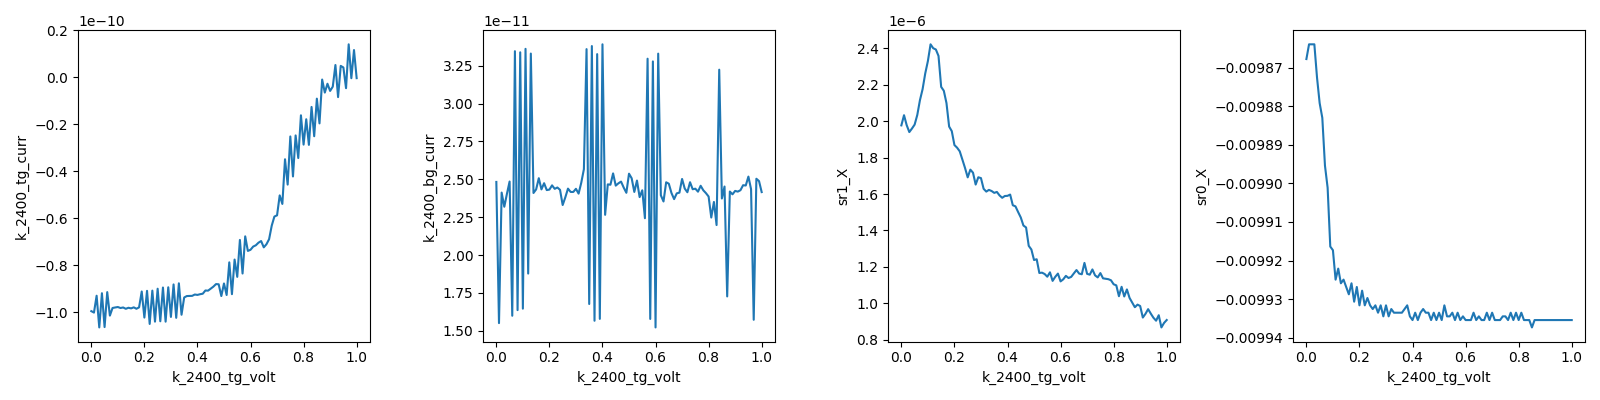

2026-08-22 23:50:19,711 [INFO] Completed in 0h 3m 49s


2026-08-22 23:50:19,712 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260822-vti-02\data\0\data.tsv.gz


2026-08-22 23:50:20,232 [INFO] Ramping k_2400_tg_volt: 1.0 -> 0


2026-08-22 23:50:22,006 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-22 23:50:22,522 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-22 23:50:22,537 [INFO] Starting sweep with ID 1


2026-08-22 23:50:22,537 [INFO] Minimum duration 0h 1m 41s


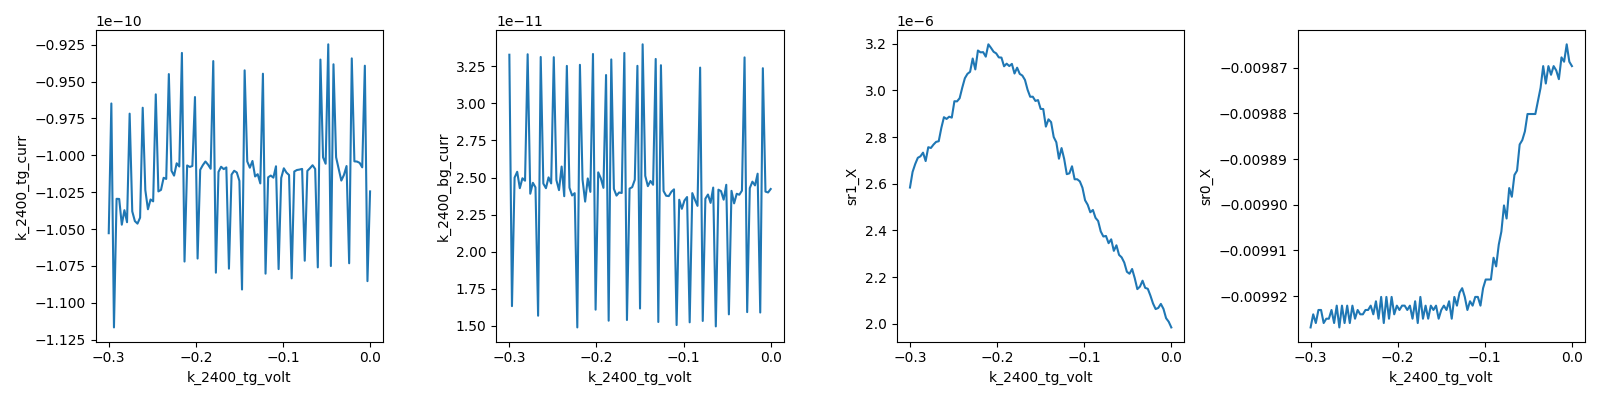

2026-08-22 23:53:53,498 [INFO] Completed in 0h 3m 30s


2026-08-22 23:53:53,499 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260822-vti-02\data\1\data.tsv.gz


2026-08-22 23:53:54,018 [INFO] Ramping k_2400_tg_volt: -0.3 -> 0


2026-08-22 23:53:54,915 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-22 23:53:55,437 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-22 23:53:55,442 [INFO] Starting sweep with ID 2


2026-08-22 23:53:55,442 [INFO] Minimum duration 0h 1m 41s


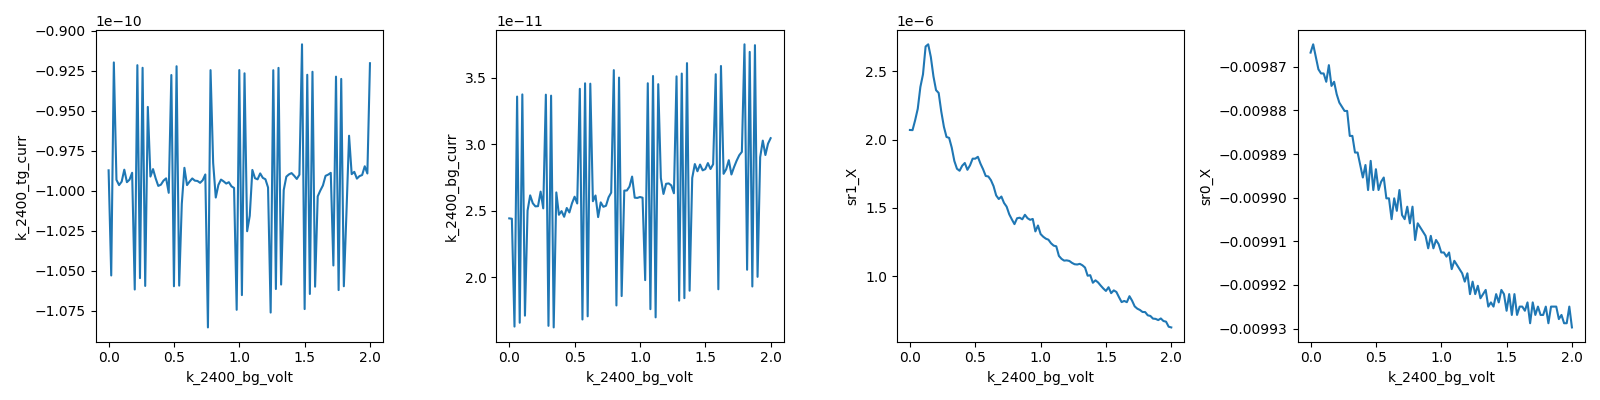

2026-08-22 23:57:29,006 [INFO] Completed in 0h 3m 33s


2026-08-22 23:57:29,007 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260822-vti-02\data\2\data.tsv.gz


2026-08-22 23:57:29,519 [INFO] Ramping k_2400_bg_volt: 2.0 -> 0


2026-08-22 23:57:32,557 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-22 23:57:33,077 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-22 23:57:33,087 [INFO] Starting sweep with ID 3


2026-08-22 23:57:33,088 [INFO] Minimum duration 0h 1m 41s


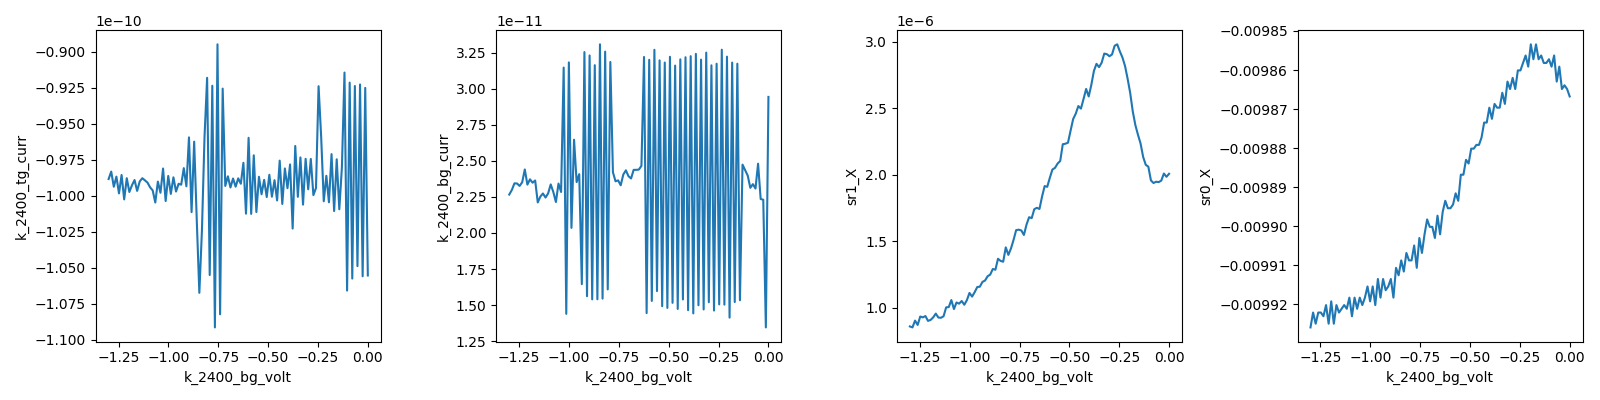

2026-08-23 00:01:05,982 [INFO] Completed in 0h 3m 32s


2026-08-23 00:01:05,982 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260822-vti-02\data\3\data.tsv.gz


2026-08-23 00:01:06,494 [INFO] Ramping k_2400_bg_volt: -1.3 -> 0


all four legs ran without a leakage trip; nplci reset to 1
k_tg.volt validator: <Numbers -0.3<=v<=1.0> | k_bg.volt validator: <Numbers -1.3<=v<=2.0>


In [18]:
# === Gate C — liveness + gross gate safety: gate-current-sanity-check (first-session branch) ===
# Four legs, each gate 0 -> each card limit with the other parked at 0, 101 pts, delay 1 s,
# nplci=10 on the gate-current channels (pA floor). Lock-in X on sr1 (B_1-B_2) + sr0 (drain)
# answer "is the device alive on the provided contacts"; gate currents answer "is it safe".
# Automatic abort: |I_gate| > 1 nA on either Keithley trips the sweep (no operator eyes in E1).
from sharpelab_nb.autorange import autorange_sr830s

# --- preconditions (state this cell assumes but does not set) ---
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
_T0 = T_sample(); _B0 = magnet.field()
print(f"precondition T_sample = {_T0:.3f} K (expect 1.0-1.5), B = {_B0:+.4f} T (expect |B|<0.02), "
      f"V_tg = {k_tg.volt():+.3f}, V_bg = {k_bg.volt():+.3f}, V_si = {k_si():+.3f} V (expect 0)")
assert 1.0 <= _T0 <= 1.5, f"T_sample {_T0} K off base"
assert abs(_B0) < 0.02, f"magnet not at zero: {_B0} T"
assert abs(k_si()) < 0.01, "Si gate not at 0"

legs = [(k_tg, TG_MAX), (k_tg, TG_MIN), (k_bg, BG_MAX), (k_bg, BG_MIN)]
n_pts, delay = 101, 1.0
I_TRIP = 1e-9   # A — hard abort threshold on either gate current

# pA-floor readback on the gate-current channels (reset at the end if no leg tripped)
k_tg.nplci(10); k_bg.nplci(10)

# sr1 sensitivity sized for an unknown Rxx: 500 uV = 50 kOhm full scale at I_bias = 10 nA
# (drive 1 V / 100 MOhm, as the operator set it); autorange hook tracks from there.
sr1.sensitivity(500e-6)
print(f"drive {sr1.amplitude()} V @ {sr1.frequency()} Hz -> I_bias ~ {sr1.amplitude()/100e6*1e9:.1f} nA; "
      f"sr0 sens {sr0.sensitivity()} V, sr1 sens {sr1.sensitivity()} V, tau {sr1.time_constant()} s")

tripped = []
for gate, v_end in legs:
    other = k_bg if gate is k_tg else k_tg
    mc = dict(meas_config); mc["comments"] = f"gate-current-sanity-check: {gate.name} 0 -> {v_end:+g} V, other gate 0, Si 0, B 0"
    s = sweep.AsyncStation(mc)
    s.add_comment('gate-current-sanity-check')
    s.add_comment(f'gate: {gate.name}; leg: 0 -> {v_end:+g} V (card limit); {other.name} parked 0; Vsi = 0; B = 0')
    s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)
    xp = gate.volt
    # row layout: [time, setpoint, other.volt, gate.curr, other.curr, T_sample, sr0.X, sr0.P, sr1.X, sr1.P]
    s.fp(other.volt).fp(gate.curr).fp(other.curr).fp(T_sample)
    s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
    s.plot(xp, k_tg.curr); s.plot(xp, k_bg.curr)
    s.plot(xp, sr1.X); s.plot(xp, sr0.X)
    s.register_run_before(autorange_sr830s, (sr0, [sr1]))

    def leak_guard(station, data, _gate=gate):
        i_g, i_o = abs(float(data[3])), abs(float(data[4]))
        if i_g > I_TRIP or i_o > I_TRIP:
            print(f"LEAK TRIP on {_gate.name} leg at V = {float(data[1]):+.3f} V: |I_swept| = {i_g:.3e}, |I_other| = {i_o:.3e} A")
            tripped.append((_gate.name, float(data[1]), i_g, i_o))
            station.interrupt_requested = True
    s.register_run_after(leak_guard, ())

    try:
        s.sweep(gate.volt, np.linspace(0, v_end, n_pts), delay=delay)
    finally:
        s.ramp(gate.volt, 0)
    if tripped:
        break

if tripped:
    print("STOP — a leg tripped the leakage guard; nplci left at 10, gates parked at 0:", tripped)
else:
    k_tg.nplci(1); k_bg.nplci(1)
    print("all four legs ran without a leakage trip; nplci reset to 1")
    print("k_tg.volt validator:", k_tg.volt.vals, "| k_bg.volt validator:", k_bg.volt.vals)


## HERA — Step 1: first 0 T gatemap (`gatemap`) → CNP line + (n, D) calibration

> **00:04** · gatemap: TG fast [-0.3,+1.0] V 66 pts x BG slow [-1.3,+1.2] V 63 rows, B 0, Vsi 0, sr1 20 uV, fast\_delay 1 s · **ETA ~01:44** (≈1h40m)

Gate C passed (runs 0–3: alive, no leakage, Rxx 60–330 Ω). The 1D legs show **two** resistance maxima through each gate (TG −0.21 / +0.11 V; BG −0.26 / +0.14 V, position ratio ≈ 0.8 ≈ c_bg/c_tg prior) — two series regions of different intrinsic doping. The map settles whether they are parallel CNP ridges (two flake domains, same lever arms) or not, fits the ridge slope for the capacitance ratio (`cnp-and-dline-calibration`), and locates the D = 0 line. Window: TG fast over its full range [−0.3, +1.0] V at 20 mV (66 pts); BG slow [−1.3, +1.2] V at 40 mV (63 rows). Coverage trade: BG is stopped at +1.2 V rather than the +2.0 V limit — from the prior, the region-A CNP line exits the TG window at V_bg ≈ +0.1 and the D = 0 line reaches V_tg = 1.0 at V_bg ≈ 1.16, so [1.2, 2.0] is metallic electron-side at finite D only, ~35 min for nothing the calibration or the fan needs. Sensitivity fixed at 20 µV (2 kΩ full scale — ×6 over the largest peak seen; a rail along the ridge at large |D| would itself be a read). Dwell: fast_delay 1 s against τ = 0.3 s / 24 dB (≈3τ — a uniform lag on a slope read, shifts the ridge intercept by ≲ 1 step, slope untouched); slow_delay 3 s. Priced from runs 0–3 (2.1 s/pt at nplci 10 + autorange reads): ≈1.3 s/pt at nplci 1 → 4158 pts ≈ 90 min + 63 row turnarounds ≈ 5 min. Leak guard (>1 nA either gate → interrupt, gates parked) stays on. Checkpoints: first two rows (signal level, sensitivity, TG current at V_tg = 1.0), then every ~15 rows for ridge continuity — abandon if the ridges rail or the map is featureless.


T_sample: VTI_sample.txt live — age 3s, period 5s
precondition T_sample = 1.166 K (1.0-1.5), B = +0.0063 T (|B|<0.02), V_si = +0.000 V (0), nplci tg/bg = 1.0/1.0 (1/1)


drive 1.0 V -> 10 nA; sr1 sens 2e-05 V (2 kOhm FS); sr0 sens 0.02 V; tau 0.3 s
2026-08-23 00:05:01,643 [INFO] Ramping k_2400_bg_volt: 0.0 -> -1.3


2026-08-23 00:05:03,362 [INFO] Ramping k_2400_tg_volt: 0.0 -> -0.3


2026-08-23 00:05:13,742 [INFO] Starting megasweep with ID 4


2026-08-23 00:05:13,744 [INFO] Minimum duration 1h 12m 27s


2026-08-23 00:08:30,008 [WARNING] ID 4 INTERRUPTED


2026-08-23 00:08:30,008 [WARNING] ID 4 INTERRUPTED


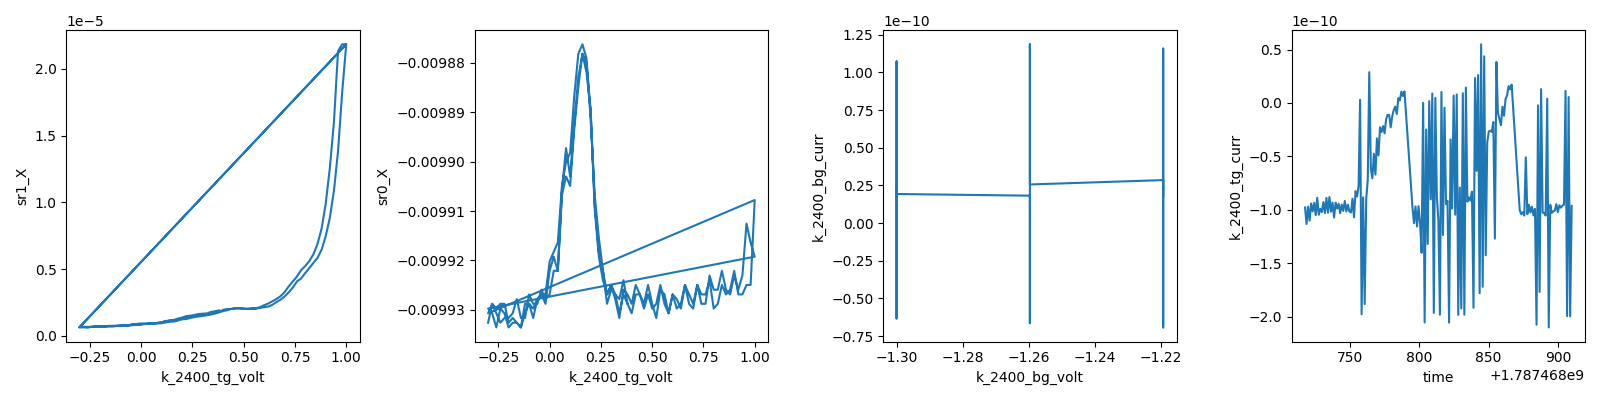

2026-08-23 00:08:30,583 [INFO] Completed in 0h 3m 16s


2026-08-23 00:08:30,584 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260822-vti-02\data\4\data.tsv.gz


2026-08-23 00:08:30,647 [INFO] Ramping k_2400_tg_volt: 0.38 -> 0


2026-08-23 00:08:31,197 [INFO] Ramping k_2400_bg_volt: -1.2195 -> 0


KeyboardInterrupt: sweep interrupted - stopping enclosing cell

In [19]:
# === 0 T gatemap (`gatemap`): TG fast [-0.3, +1.0] V x BG slow [-1.3, +1.2] V, 20 x 40 mV ===
# --- preconditions (assumed, not set) ---
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
_T0, _B0 = T_sample(), magnet.field()
print(f"precondition T_sample = {_T0:.3f} K (1.0-1.5), B = {_B0:+.4f} T (|B|<0.02), V_si = {k_si():+.3f} V (0), "
      f"nplci tg/bg = {k_tg.nplci()}/{k_bg.nplci()} (1/1)")
assert 1.0 <= _T0 <= 1.5 and abs(_B0) < 0.02 and abs(k_si()) < 0.01
assert k_tg.nplci() == 1 and k_bg.nplci() == 1, "gate-current nplci not reset to 1"

Vtg_vec = np.linspace(-0.3, 1.0, 66)    # fast, 20 mV
Vbg_vec = np.linspace(-1.3, 1.2, 63)    # slow, 40 mV
assert Vtg_vec.min() >= TG_MIN and Vtg_vec.max() <= TG_MAX and Vbg_vec.min() >= BG_MIN and Vbg_vec.max() <= BG_MAX
FAST_DELAY, SLOW_DELAY = 1.0, 3.0
I_TRIP = 1e-9

# Fixed sensitivity for the whole map (no autorange mid-row): 20 uV = 2 kOhm full scale at 10 nA.
sr1.sensitivity(20e-6)
print(f"drive {sr1.amplitude()} V -> 10 nA; sr1 sens {sr1.sensitivity()} V (2 kOhm FS); sr0 sens {sr0.sensitivity()} V; tau {sr1.time_constant()} s")

mc = dict(meas_config); mc["Si (V)"] = k_si(); mc["sample_temperature:"] = _T0
mc["comments"] = "gatemap: TG fast -0.3..+1.0 V (66), BG slow -1.3..+1.2 V (63), B = 0, Vsi = 0, sr1 sens 20 uV"
s = sweep.AsyncStation(mc)
s.add_comment('gatemap')
s.add_comment('TG fast [-0.3, +1.0] V 66 pts (20 mV); BG slow [-1.3, +1.2] V 63 rows (40 mV); B = 0; Vsi = 0; first map of cooldown')
s.ramp(k_bg.volt, Vbg_vec[0]); s.ramp(k_tg.volt, Vtg_vec[0])
interruptible_sleep(10)

# row layout: [time, Vbg(slow), Vtg(fast), T_sample, k_tg.curr, k_bg.curr, sr0.X, sr0.P, sr1.X, sr1.P]
s.fp(T_sample).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
s.plot(k_tg.volt, sr1.X); s.plot(k_tg.volt, sr0.X)
s.plot(k_bg.volt, k_bg.curr); s.plot('time', k_tg.curr)

def leak_guard(station, data):
    i_tg, i_bg = abs(float(data[4])), abs(float(data[5]))
    if i_tg > I_TRIP or i_bg > I_TRIP:
        print(f"LEAK TRIP at Vbg={float(data[1]):+.3f}, Vtg={float(data[2]):+.3f}: |I_tg|={i_tg:.3e}, |I_bg|={i_bg:.3e} A")
        station.interrupt_requested = True
s.register_run_after(leak_guard, ())

try:
    s.megasweep(k_bg.volt, Vbg_vec, k_tg.volt, Vtg_vec, slow_delay=SLOW_DELAY, fast_delay=FAST_DELAY)
finally:
    s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)


## HERA — gatemap re-run at 100 µV (run 4 aborted at the first-rows checkpoint)

> **00:09** · gatemap re-run: TG fast [-0.3,+1.0] V 66 x BG slow [-1.3,+1.2] V 63, B 0, Vsi 0, sr1 100 uV (10 kOhm FS) · **ETA ~01:44** (≈1h35m)

Run 4 railed `sr1` (2.18 kΩ, fs 1.09) along the CNP ridge on its first two rows (V_bg = −1.3, D ≈ +0.3 V/nm): the gapped CNP at large |D| already exceeds the 2 kΩ full scale chosen from the D ≈ 0 peaks, so the ridge rows the slope fit needs most would be flat-topped. Aborted at 3 min (interrupted, gates parked at 0). Same map at **100 µV = 10 kΩ full scale** — the expert rule: lose low-R resolution (60 Ω = 0.6 % of range, readable per runs 0–3 at 0.4 %) rather than saturate. Everything else unchanged: TG fast [−0.3, +1.0] V 66 pts, BG slow [−1.3, +1.2] V 63 rows, fast_delay 1 s, leak guard on. Run-4 rate: 48–50 rows/min → 4158 pts ≈ 85 min + turnarounds. Same checkpoints: first rows (rail?), then every ~15 rows.


T_sample: VTI_sample.txt live — age 4s, period 5s
precondition T_sample = 1.166 K (1.0-1.5), B = +0.0063 T (|B|<0.02), V_si = +0.000 V (0), nplci tg/bg = 1.0/1.0 (1/1)


drive 1.0 V -> 10 nA; sr1 sens 0.0001 V (10 kOhm FS); sr0 sens 0.02 V; tau 0.3 s
2026-08-23 00:09:25,281 [INFO] Ramping k_2400_bg_volt: 0.0 -> -1.3


2026-08-23 00:09:27,006 [INFO] Ramping k_2400_tg_volt: 0.0 -> -0.3


2026-08-23 00:09:37,382 [INFO] Starting megasweep with ID 5


2026-08-23 00:09:37,383 [INFO] Minimum duration 1h 12m 27s


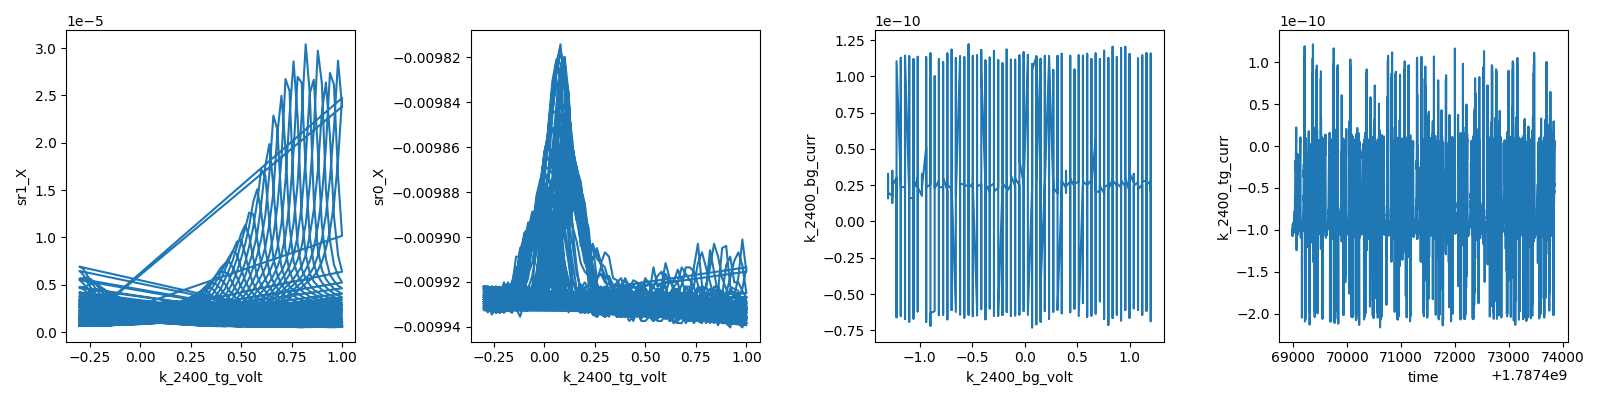

2026-08-23 01:30:51,166 [INFO] Completed in 1h 21m 13s


2026-08-23 01:30:51,167 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260822-vti-02\data\5\data.tsv.gz


2026-08-23 01:30:51,229 [INFO] Ramping k_2400_tg_volt: 1.0 -> 0


2026-08-23 01:30:52,556 [INFO] Ramping k_2400_bg_volt: 1.2 -> 0


In [20]:
# === 0 T gatemap (`gatemap`): TG fast [-0.3, +1.0] V x BG slow [-1.3, +1.2] V, 20 x 40 mV ===
# --- preconditions (assumed, not set) ---
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
_T0, _B0 = T_sample(), magnet.field()
print(f"precondition T_sample = {_T0:.3f} K (1.0-1.5), B = {_B0:+.4f} T (|B|<0.02), V_si = {k_si():+.3f} V (0), "
      f"nplci tg/bg = {k_tg.nplci()}/{k_bg.nplci()} (1/1)")
assert 1.0 <= _T0 <= 1.5 and abs(_B0) < 0.02 and abs(k_si()) < 0.01
assert k_tg.nplci() == 1 and k_bg.nplci() == 1, "gate-current nplci not reset to 1"

Vtg_vec = np.linspace(-0.3, 1.0, 66)    # fast, 20 mV
Vbg_vec = np.linspace(-1.3, 1.2, 63)    # slow, 40 mV
assert Vtg_vec.min() >= TG_MIN and Vtg_vec.max() <= TG_MAX and Vbg_vec.min() >= BG_MIN and Vbg_vec.max() <= BG_MAX
FAST_DELAY, SLOW_DELAY = 1.0, 3.0
I_TRIP = 1e-9

# Fixed sensitivity for the whole map (no autorange mid-row): 100 uV = 10 kOhm full scale at 10 nA.
sr1.sensitivity(100e-6)
print(f"drive {sr1.amplitude()} V -> 10 nA; sr1 sens {sr1.sensitivity()} V (10 kOhm FS); sr0 sens {sr0.sensitivity()} V; tau {sr1.time_constant()} s")

mc = dict(meas_config); mc["Si (V)"] = k_si(); mc["sample_temperature:"] = _T0
mc["comments"] = "gatemap: TG fast -0.3..+1.0 V (66), BG slow -1.3..+1.2 V (63), B = 0, Vsi = 0, sr1 sens 100 uV; re-run of run 4 (railed at 2 kOhm)"
s = sweep.AsyncStation(mc)
s.add_comment('gatemap')
s.add_comment('TG fast [-0.3, +1.0] V 66 pts (20 mV); BG slow [-1.3, +1.2] V 63 rows (40 mV); B = 0; Vsi = 0; first map of cooldown')
s.ramp(k_bg.volt, Vbg_vec[0]); s.ramp(k_tg.volt, Vtg_vec[0])
interruptible_sleep(10)

# row layout: [time, Vbg(slow), Vtg(fast), T_sample, k_tg.curr, k_bg.curr, sr0.X, sr0.P, sr1.X, sr1.P]
s.fp(T_sample).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
s.plot(k_tg.volt, sr1.X); s.plot(k_tg.volt, sr0.X)
s.plot(k_bg.volt, k_bg.curr); s.plot('time', k_tg.curr)

def leak_guard(station, data):
    i_tg, i_bg = abs(float(data[4])), abs(float(data[5]))
    if i_tg > I_TRIP or i_bg > I_TRIP:
        print(f"LEAK TRIP at Vbg={float(data[1]):+.3f}, Vtg={float(data[2]):+.3f}: |I_tg|={i_tg:.3e}, |I_bg|={i_bg:.3e} A")
        station.interrupt_requested = True
s.register_run_after(leak_guard, ())

try:
    s.megasweep(k_bg.volt, Vbg_vec, k_tg.volt, Vtg_vec, slow_delay=SLOW_DELAY, fast_delay=FAST_DELAY)
finally:
    s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)


## HERA — Step 3: SdH spot check, electron side (`sdh-spot-check`), n = +3.2×10¹² at D = 0, B 0 → 10 T

> **01:33** · sdh-spot-check e-side: n=+3.2e12 D=0 (Vtg +0.984, Vbg +1.166), B 0->10 T, 50 mT to 1 T then 10 mT, delay 0 (3 s settle), sr1 50 uV; ends at 10 T · **ETA ~03:48** (≈2h15m)

Calibration from run 5 (ana): c_bg/c_tg = 0.773 (data), c_tg = 2.796 mF/m² (9.5 nm prior), n_offset −0.089×10¹², D_offset −0.013 V/nm (R_CNP(D) symmetry). The D = 0 line inside the validators spans n = −1.27 … +3.27×10¹², so the electron side is the high-|n| side: spot at **n = +3.2×10¹²** → (V_tg, V_bg) = (+0.984, +1.166) V, 16 mV under the TG limit. **Feasibility (Step 2, model table):** F_L = 33.1 T; ABAB pair ≈ 7.5 / 25.6 T (m* 0.028 / 0.061 mₑ), ABCA singleton 33.1 T (m* 0.074); the heavy-ABAB-vs-ABCA split is 7.5 T. Grid: uniform in B (blocking magnet) — 50 mT from 0 to 1 T (MR background only; LK at T_e ≈ 8 K kills m* = 0.06 below ~1.5 T), **10 mT from 1 to 10 T**; 921 points. Dwell: `delay = 0` — each `magnet.field` set blocks through the ramp plus the driver's 3 s settle = 10 τ at τ = 0.3 s / 24 dB, i.e. the lock-in is at the settling floor at every point. Sensitivity fixed at 50 µV (5 kΩ FS): R(B = 0) ≈ 70 Ω is 1.4 % of range, but there is no SdH below ~1.5 T and the MR + SdH maxima at high B need the headroom; the FFT window starts above onset. **Price:** 10 T bare traverse 73 min + 921 × ~3.8 s per-point overhead (settle 3 s + reads) ≈ 58 min → **≈ 2 h 15 m**, ending at **10 T with the gates at the spot** — the hole-side spot check (n = −1.2×10¹²) then rides the magnet down 10 → 0.3 T, never re-traversing. Checkpoints: first 20 points (signal, sensitivity, leakage, field readback tracking setpoints); at ~3 T and ~6 T a partial FFT on the landed record (onset, tone count) — abort if the channel rails or no oscillation content has appeared by 6 T with R flat (then the fan is pointless at this T_e and the read is resolution-limited).


spot: n = +3.20e12, D = +0.00 V/nm -> (Vtg, Vbg) = (+0.9836, +1.1661) V; roundtrip n,D = (3.2, -1.734723475976807e-18)
T_sample: VTI_sample.txt live — age 1s, period 5s
precondition T_sample = 1.166 K (1.0-1.5), B = +0.0063 T (|B|<0.05: sweep starts at 0), V_si = +0.000 V (0), PS heater True, output True


B grid: 921 pts, 0.0 -> 10.0 T; sr1 sens 5e-05 V, tau 0.3 s (settle_s 3.0 s = dwell)
2026-08-23 01:33:34,864 [INFO] Ramping k_2400_bg_volt: 0.0 -> 1.1661246961468763


2026-08-23 01:33:36,400 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0.9836210126989271


2026-08-23 01:33:47,646 [INFO] Starting sweep with ID 6


2026-08-23 01:33:47,646 [INFO] Minimum duration 0h 0m 0s


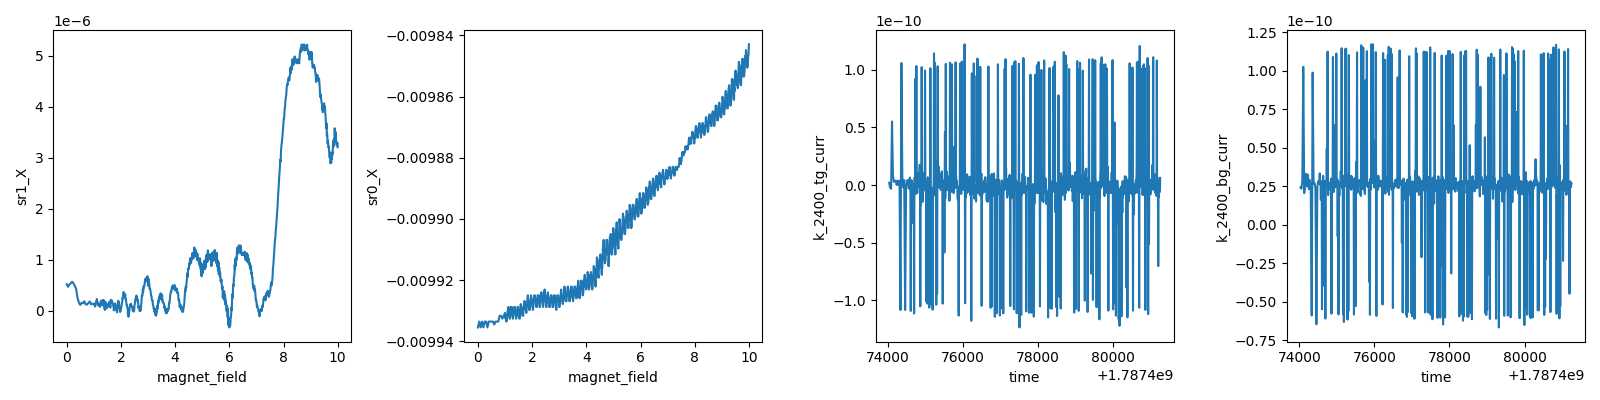

2026-08-23 03:34:09,902 [INFO] Completed in 2h 0m 21s


2026-08-23 03:34:09,903 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260822-vti-02\data\6\data.tsv.gz


done: B = +10.008 T, (Vtg, Vbg) = (+0.9835, +1.1660)


In [21]:
# === SdH spot check, electron side (`sdh-spot-check`): n = +3.2e12 at D = 0 (region-A calibration), B 0 -> 10 T ===
from sharpelab_nb.gates import calc_gate_voltages, calc_nD

# --- session calibration from run 5 (cnp-and-dline-calibration; ratio data-calibrated, scale = geometry prior) ---
CAL = dict(c_tg=2.796e-03, c_bg=2.161e-03, n_offset=-0.0894, D_offset=-0.013)
n_spot, D_spot = 3.2, 0.0                       # 1e12 cm^-2, V/nm
Vtg_spot, Vbg_spot = calc_gate_voltages(n_spot, D_spot, CAL["c_tg"], CAL["c_bg"], CAL["n_offset"], CAL["D_offset"])
assert TG_MIN <= Vtg_spot <= TG_MAX and BG_MIN <= Vbg_spot <= BG_MAX, (Vtg_spot, Vbg_spot)
print(f"spot: n = {n_spot:+.2f}e12, D = {D_spot:+.2f} V/nm -> (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}) V; "
      f"roundtrip n,D = {calc_nD(Vtg_spot, Vbg_spot, CAL['c_tg'], CAL['c_bg'], CAL['n_offset'], CAL['D_offset'])}")

# --- preconditions (assumed, not set) ---
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
_T0, _B0 = T_sample(), magnet.field()
print(f"precondition T_sample = {_T0:.3f} K (1.0-1.5), B = {_B0:+.4f} T (|B|<0.05: sweep starts at 0), V_si = {k_si():+.3f} V (0), "
      f"PS heater {magnet.persistent_switch_on()}, output {magnet.output_enabled()}")
assert 1.0 <= _T0 <= 1.5 and abs(_B0) < 0.05 and abs(k_si()) < 0.01
assert magnet.persistent_switch_on() and magnet.output_enabled()

# --- field grid: uniform in B (blocking rate-limited magnet). 50 mT to 1 T (background only), 10 mT 1 -> 10 T:
B_vec = np.unique(np.round(np.hstack((np.arange(0.0, 1.0, 0.05), np.arange(1.0, 10.0001, 0.01))), 4))
assert B_vec.max() <= B_SESSION_CAP
I_TRIP = 1e-9
# Fixed sensitivity: 50 uV = 5 kOhm full scale at 10 nA (R(B=0) ~ 70 Ohm = 1.4 % FS; MR + SdH maxima at high B size the headroom).
sr1.sensitivity(50e-6)
print(f"B grid: {len(B_vec)} pts, {B_vec[0]} -> {B_vec[-1]} T; sr1 sens {sr1.sensitivity()} V, tau {sr1.time_constant()} s (settle_s {magnet.settle_s} s = dwell)")

mc = dict(meas_config); mc["Si (V)"] = k_si(); mc["sample_temperature:"] = _T0
mc["comments"] = f"sdh-spot-check electron: n = {n_spot:+.2f}e12, D = {D_spot:+.2f} V/nm (run-5 cal), (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}), B 0 -> 10 T, 10 mT above 1 T, sr1 50 uV"
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment(f'electron side: n = {n_spot:+.2f}e12 cm^-2, D = {D_spot:+.2f} V/nm; (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}); '
              f'B 0 -> 10 T uniform-B (50 mT to 1 T, 10 mT above); cal run 5: ratio {CAL["c_bg"]/CAL["c_tg"]:.3f}, n_offset {CAL["n_offset"]:+.3f}e12, D_offset {CAL["D_offset"]:+.3f}')
s.ramp(k_bg.volt, Vbg_spot); s.ramp(k_tg.volt, Vtg_spot)
interruptible_sleep(10)

# row layout: [time, B, T_sample, k_tg.curr, k_bg.curr, sr0.X, sr0.P, sr1.X, sr1.P]
s.fp(T_sample).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
s.plot(magnet.field, sr1.X); s.plot(magnet.field, sr0.X); s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)

def leak_guard(station, data):
    i_tg, i_bg = abs(float(data[3])), abs(float(data[4]))
    if i_tg > I_TRIP or i_bg > I_TRIP:
        print(f"LEAK TRIP at B={float(data[1]):+.3f} T: |I_tg|={i_tg:.3e}, |I_bg|={i_bg:.3e} A")
        station.interrupt_requested = True
s.register_run_after(leak_guard, ())

s.sweep(magnet.field, B_vec, delay=0)
# gates stay at the spot; field stays at 10 T (the hole-side spot check rides it down) — no park here.
print(f"done: B = {magnet.field():+.3f} T, (Vtg, Vbg) = ({k_tg.volt():+.4f}, {k_bg.volt():+.4f})")


## HERA — Step 3b: SdH spot check, hole side (`sdh-spot-check`), n = −1.2×10¹² at D = 0, riding the magnet 10 → 0.3 T

> **03:34** · sdh-spot-check h-side: n=-1.2e12 D=0 (Vtg -0.280, Vbg -0.463), B 10->0.3 T, 20 mT, delay 0, sr1 50 uV; ends at 0.3 T · **ETA ~05:19** (≈1h45m)

Run 6 (electron, n = +3.2×10¹²) ends at 10 T with the gates at the spot. The investigation takes both signs (no side prior); the hole side of the D = 0 line reaches only n = −1.27×10¹² (TG −0.3 V limit), so the spot sits at **n = −1.2×10¹²** → (V_tg, V_bg) = (−0.280, −0.463) V. Feasibility (model): F_L = 12.4 T; ABAB pair ≈ 5.3 / 7.1 T (the near-CNP semimetal regime, tones close and balanced — the recipe's stated low-|n| exception), ABCA 12.4 T with m* ≈ 1 mₑ — LK-dead at this rig's T_e ≈ 8 K. **Coverage trade, stated:** this is a cheap preview, not a decisive read — it costs ~35 min over the bare 10 → 0 T ramp the session needs anyway, and a null here is resolvability-limited, not evidence. Grid: 20 mT uniform in B descending, 486 pts, delay 0 (3 s driver settle = 10 τ). Sensitivity 50 µV (5 kΩ FS; R(B = 0) ≈ 250–300 Ω this close to the CNP, MR headroom). Price: 9.7 T traverse 71 min + 486 × ~3.8 s ≈ 31 min → **≈ 1 h 45 m**, ending at 0.3 T. Checkpoints: first 20 points (rail? the CNP side at 10 T could be large), then the ana read at the end together with run 6.


spot: n = -1.20e12, D = +0.00 V/nm -> (Vtg, Vbg) = (-0.2770, -0.4650) V; roundtrip n,D = (-1.2000000000000002, 3.469446951953614e-18)
T_sample: VTI_sample.txt live — age 2s, period 5s
precondition T_sample = 1.291 K (1.0-1.5), B = +10.0063 T (expect 10 T: the electron spot check ended there), V_si = +0.000 V (0), PS heater True, output True


B grid: 486 pts, 10.0 -> 0.3 T; sr1 sens 5e-05 V, tau 0.3 s (settle_s 3.0 s = dwell)
2026-08-23 03:35:04,125 [INFO] Ramping k_2400_bg_volt: 1.166 -> -0.46496674059537246


2026-08-23 03:35:06,258 [INFO] Ramping k_2400_tg_volt: 0.9835 -> -0.2770329911637339


2026-08-23 03:35:17,854 [INFO] Starting sweep with ID 7


2026-08-23 03:35:17,855 [INFO] Minimum duration 0h 0m 0s


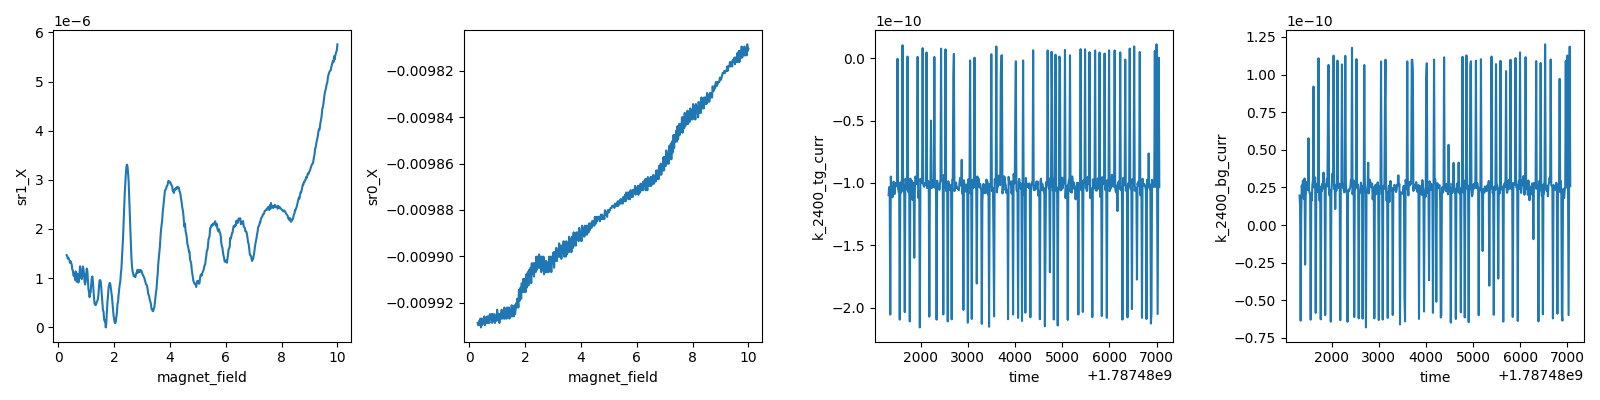

2026-08-23 05:10:59,262 [INFO] Completed in 1h 35m 40s


2026-08-23 05:10:59,263 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260822-vti-02\data\7\data.tsv.gz


done: B = +0.303 T, (Vtg, Vbg) = (-0.2770, -0.4650)


In [22]:
# === SdH spot check, hole side (`sdh-spot-check`): n = -1.2e12 at D = 0 (region-A calibration), rides the magnet 10 -> 0.3 T ===
from sharpelab_nb.gates import calc_gate_voltages, calc_nD

# --- session calibration from run 5 (cnp-and-dline-calibration; ratio data-calibrated, scale = geometry prior) ---
CAL = dict(c_tg=2.796e-03, c_bg=2.161e-03, n_offset=-0.0894, D_offset=-0.013)
n_spot, D_spot = -1.2, 0.0                      # 1e12 cm^-2, V/nm (D = 0 line reaches -1.27 on this side)
Vtg_spot, Vbg_spot = calc_gate_voltages(n_spot, D_spot, CAL["c_tg"], CAL["c_bg"], CAL["n_offset"], CAL["D_offset"])
assert TG_MIN <= Vtg_spot <= TG_MAX and BG_MIN <= Vbg_spot <= BG_MAX, (Vtg_spot, Vbg_spot)
print(f"spot: n = {n_spot:+.2f}e12, D = {D_spot:+.2f} V/nm -> (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}) V; "
      f"roundtrip n,D = {calc_nD(Vtg_spot, Vbg_spot, CAL['c_tg'], CAL['c_bg'], CAL['n_offset'], CAL['D_offset'])}")

# --- preconditions (assumed, not set) ---
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
_T0, _B0 = T_sample(), magnet.field()
print(f"precondition T_sample = {_T0:.3f} K (1.0-1.5), B = {_B0:+.4f} T (expect 10 T: the electron spot check ended there), V_si = {k_si():+.3f} V (0), "
      f"PS heater {magnet.persistent_switch_on()}, output {magnet.output_enabled()}")
assert 1.0 <= _T0 <= 1.5 and abs(_B0 - 10.0) < 0.05 and abs(k_si()) < 0.01
assert magnet.persistent_switch_on() and magnet.output_enabled()

# --- field grid: uniform in B, descending (blocking magnet; start where it sits). F_L(1.2e12) = 12.4 T.
B_vec = np.unique(np.round(np.arange(10.0, 0.2999, -0.02), 4))[::-1]   # 10 -> 0.3 T, 20 mT
assert B_vec.max() <= B_SESSION_CAP
I_TRIP = 1e-9
# Fixed sensitivity: 50 uV = 5 kOhm FS at 10 nA (R(B=0) ~ 250-300 Ohm near the CNP side; MR + SdH maxima at 10 T size the headroom).
sr1.sensitivity(50e-6)
print(f"B grid: {len(B_vec)} pts, {B_vec[0]} -> {B_vec[-1]} T; sr1 sens {sr1.sensitivity()} V, tau {sr1.time_constant()} s (settle_s {magnet.settle_s} s = dwell)")

mc = dict(meas_config); mc["Si (V)"] = k_si(); mc["sample_temperature:"] = _T0
mc["comments"] = f"sdh-spot-check hole: n = {n_spot:+.2f}e12, D = {D_spot:+.2f} V/nm (run-5 cal), (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}), B 10 -> 0.3 T, 20 mT, sr1 50 uV"
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment(f'hole side: n = {n_spot:+.2f}e12 cm^-2, D = {D_spot:+.2f} V/nm; (Vtg, Vbg) = ({Vtg_spot:+.4f}, {Vbg_spot:+.4f}); '
              f'B 10 -> 0.3 T uniform-B 20 mT (ride-down); cal run 5: ratio {CAL["c_bg"]/CAL["c_tg"]:.3f}, n_offset {CAL["n_offset"]:+.3f}e12, D_offset {CAL["D_offset"]:+.3f}')
s.ramp(k_bg.volt, Vbg_spot); s.ramp(k_tg.volt, Vtg_spot)
interruptible_sleep(10)

# row layout: [time, B, T_sample, k_tg.curr, k_bg.curr, sr0.X, sr0.P, sr1.X, sr1.P]
s.fp(T_sample).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.P)
s.plot(magnet.field, sr1.X); s.plot(magnet.field, sr0.X); s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)

def leak_guard(station, data):
    i_tg, i_bg = abs(float(data[3])), abs(float(data[4]))
    if i_tg > I_TRIP or i_bg > I_TRIP:
        print(f"LEAK TRIP at B={float(data[1]):+.3f} T: |I_tg|={i_tg:.3e}, |I_bg|={i_bg:.3e} A")
        station.interrupt_requested = True
s.register_run_after(leak_guard, ())

s.sweep(magnet.field, B_vec, delay=0)
# gates stay at the spot; field ends at 0.3 T — no park here.
print(f"done: B = {magnet.field():+.3f} T, (Vtg, Vbg) = ({k_tg.volt():+.4f}, {k_bg.volt():+.4f})")


## Operator — handoff

Returned the rig to its bring-up state before restarting the agent instance: state0 replayed, gates 0 V, field 0 T. Readback below.

In [23]:
# Operator — handoff: return to the bring-up state (state0) with the field at 0 T. Blocks ~3 min from 0.3 T.
from sharpelab_nb.closeout import close_out
close_out(
    (magnet.field, 0.0),
    restore=state0,
    gates=[(k_tg.volt, 0.0), (k_bg.volt, 0.0), (k_si, 0.0)],
    extra_readback={"T_sample": T_sample, "T_vaporizer": T_vaporizer,
                    "sample_range": heater.sample_range, "vaporizer_range": heater.vaporizer_range,
                    "PS_on": magnet.persistent_switch_on, "output_enabled": magnet.output_enabled,
                    "Si_V": dc205.voltage, "dc205_range": dc205.voltage_range, "dc205_output": dc205.output},
)

-- restore (19 params)
-- gates
-- field -> 0.0

--- close-out readback ---
drive_V : 1.0  <Numbers 0.004<=v<=5.0>
drive_Hz : 13.777  <Numbers 0.001<=v<=102000.0>
sr0_sens : 0.02  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr0_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr0_slope : 24  <Enum: {24, 18, 12, 6}>
sr1_sens : 2e-06  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr1_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr1_slope : 24  <Enum: {24, 18, 12, 6}>
sr2_sens : 0.0001  <Enum: {0.2, 0.5, 2e-09, 1, 1e-

## Operator — kernel-binding probe, re-run after the handoff

Same kernel, nothing restarted. HERA's probe cell ([16], `KERNEL PROBE: BOUND`) re-run here so the incoming instance sees the binding confirmed; the [VERIFY] record in `session_notes.md` stands.

In [24]:
# === Kernel-binding probe (read-only) ===
# First E1 act after the grant: confirms the nb-collab execute path lands on the
# operator's instrument-carrying kernel (the one that ran Setup + SAFETIES), not
# a fresh python3 kernel. Touches no instrument — namespace only.
import os
_need = ['magnet', 'heater', 'sr0', 'sr1', 'sr2', 'sr3', 'k_2400_tg', 'k_2400_bg',
         'dc205', 'k_tg', 'k_bg', 'k_si', 'T_sample', 'T_vaporizer', 'meas_config',
         'WIRING', 'state0', 'cal', 'B_SESSION_CAP', 'T_SESSION_CAP', 'tg_lims', 'bg_lims']
_missing = [n for n in _need if n not in globals()]
print(f"pid {os.getpid()} | main_dir {main_dir if 'main_dir' in globals() else '<unset>'}")
print(f"present: {len(_need) - len(_missing)}/{len(_need)} | missing: {_missing}")
print("KERNEL PROBE:", "BOUND" if not _missing else "UNBOUND")

pid 37460 | main_dir C:\Users\DGG\VTI_local_data\zack\20260822-vti-02
present: 22/22 | missing: []
KERNEL PROBE: BOUND


## HERA — electron Landau fan for the stacking investigation

> **05:25** · D=0 electron Landau fan: n=+2.8..+3.2e12 cm^-2, B=1.03091->7.05 T uniform 1/B, 238x10, base T, Si=0 V, sr1 50uV, 3s settle · **ETA ~09:10** (≈3h45m)

`landau-fan-vti` under `tetralayer-stacking-fs-count` Step 4. Gate C passed (runs 0–3); run 5 locates the CNP and D≈0 line. Spot checks 6/7 are now analyzed in ana cells 14–15: electron frequency components near 7.3/14.7/22.2/29.5 T are more reproducible than the near-CNP hole spectrum, but their harmonic/pocket identities remain unresolved. This fan measures their density trajectories and repeats +3.2 on a changed field grid. Only B_1–B_2 is wired; the two CNP ridges within that path are a spatial-inhomogeneity confound, not two separately measurable regions.

**Design and resolution.** D=0 in the same run-6 rounded calibration (ratio data-calibrated, scale geometry-prior). n=+2.8…+3.2×10¹² cm⁻², 10 paired gate points; TG +0.869016…+0.983621 V, BG +1.017844…+1.166125 V, Si unchanged at 0. B=1.0309096914→7.05 T, 238 rows uniform in 1/B. `sdh_onset(run6, b_hi=4, bg_degree=5)` supplies B_lo; the full 10 T fit is background-sensitive/censored, and degree 3 makes the ~7 T tone marginal (robust headline 1.38 T). This onset fork is carried explicitly: do not infer partner absence from the nominal full window alone.

Model `fs_count_b0.abab_fs` predicts (light,heavy) = (6.038,22.914), (6.673,24.351), (7.306,25.783) T at n=2.8,3.0,3.2; ABCA F_L=28.950…33.085 T. The nominal inverse-field span is 0.82817 T⁻¹, δF=1.2075 T, five periods of the smallest nominal ABAB partner, and heavy/singleton separation ≥6.04 T >2δF. A higher actual onset or a lower global density scale reduces that period count; it limits confidence rather than licensing a hidden redefinition of the window. Δn=0.04444×10¹² gives 2.24 samples per g=4 ray at B_lo (floor N_n=10). Δ(1/B)=0.0034944 T⁻¹ gives Nyquist 143.09 T: although F_L alone permits coarser sampling, run 6 tracks higher components through ~130 T and a coarser fan would alias them into putative pockets. N_B=238 is the floor at the chosen 0.0035 spacing. The +3.2 column must reproduce run 6 before a new frequency claim is trusted.

**Coverage trade.** This is the high-electron discriminating slice. Lower electron densities enter the nearly empty-partner exception and fail the five-period criterion in this window; the gate-limited hole range (only to −1.27×10¹² at D=0) never reaches the separated-template design regime. Extending across the entire allowed D=0 density interval at this ray spacing would need ~103 density points and roughly 25 h with this acquisition, while still not repairing the low-density period deficit. The present 0.4×10¹² span limits slope discrimination; report unresolved harmonics/model families honestly, and do not claim a whole-device stacking order.

**Acquisition and cost.** Fixed sr1 50 μV (5 kΩ nominal FS), sr0 20 mV, drive 1 V/100 MΩ=10 nA. Run 6 max |R|≈530 Ω through 10 T; allow a factor 3 for the lower-n corner (~1.6 kΩ), well inside 5 kΩ. Both active lock-ins retain τ=0.3 s / 24 dB: every point settles 3 s=10τ, matching the spot check's magnet dwell. No autorange. Run 5 at NPLC1 measured median 1.0985 s/point with 1 s dwell; budget 3.15 s/point for the paired gates and extra temperature read. 2,380×3.15 s=125 min; monotonic 0→7.05 T at 1 A/min and 1/7.3 T/A adds 51.5 min (initial 0→1.031 T included); 238×4.5 s row overhead adds 17.9 min, consistent with run 6's ~3.08 s non-ramp overhead plus flyback/slow-delay. Add setup and 15% margin. Leave B=7.05 T and gates at the +3.2 endpoint for a subsequent measured descent; no blind return traverse.

**Preflight and checkpoints.** The cell rechecks committed validators numerically against the card, base temperature with fresh sample/vaporizer logs, heaters off, field at zero, output/PS on, Si state, hardwired routing, excitation, τ/slope, and gate pacing/NPLC. It changes no safety surface. All followed values have live plots. Per-point guards stop for |I_gate|>1 nA, off-base T/stale logs, near-full-scale lock-ins, or lost current. Inspect the first three landed rows (~10 min including positioning), then every 30 min and at B≈2,4,6 T: leakage, current continuity, clipping, dead channels, row timing; continue only if clean. After ≥2 T compare the shared density with run 6; later fit F(n) with both ABAB and trilayer overlays and one global scale. Interrupting a VTI cell does **not** stop an in-progress magnet ramp: the supply continues to its last target; notify the operator for a ramp emergency, and re-read actual state after any abort.


In [ ]:
# landau-fan-vti: paired D=0 n-line, monotonic positive-B fan.
# Preconditions are read-only; do not change validators, ramp steps, or pacing.
from sharpelab_nb.gates import calc_gate_voltages
for _p, _expected in ((k_tg.volt,(-0.3,1.0)),(k_bg.volt,(-1.3,2.0)),
        (dc205.smart_voltage,(-25.,25.)),(dc205.voltage,(-25.,25.)),
        (magnet.field,(-10.,10.)),(heater.sample_setpoint,(0.,100.)),
        (heater.vaporizer_setpoint,(0.,100.))):
    _actual=(float(_p.vals._min_value),float(_p.vals._max_value))
    print(f'{_p.full_name} validator: expected {_expected}, actual {_actual}')
    assert _actual==_expected
assert B_SESSION_CAP==10 and T_SESSION_CAP==100
for _name in ('T_sample','T_vaporizer'):
    assert_thermometry_live(_name,VTI.temp_logfile_candidates[_name],max_age=15,max_period=12)
_Ts,_Tv,_B=T_sample(),T_vaporizer(),magnet.field()
_Si=k_si(); _ranges=(heater.sample_range(),heater.vaporizer_range())
_PS,_out=magnet.persistent_switch_on(),magnet.output_enabled()
print(f'Expected base Ts 1.0..1.5, Tv 0.5..1.6 K, B~0 T, Si=0, heaters off, PS/output on; actual {_Ts}, {_Tv}, {_B}, {_Si}, {_ranges}, {_PS}/{_out}')
assert 1.0<=_Ts<=1.5 and .5<=_Tv<=1.6 and abs(_Tv-_Ts)<.6
assert abs(_B)<.02 and abs(_Si)<.01 and _ranges==(0,0) and _PS and _out
assert dc205.voltage_range()==2 and dc205.output()==1 and dc205.ramp_rate==.5
assert k_tg is k_2400_tg and k_bg is k_2400_bg and k_si is dc205.smart_voltage
assert WIRING=={'source':'T_0','drain':'B_3','sr1+':'B_1','sr1-':'B_2',
               'sr2+':'n.c.','sr2-':'n.c.','sr3+':'n.c.','sr3-':'n.c.'}
for _li in (sr0,sr1):
    _tau,_slope=_li.time_constant(),_li.filter_slope()
    print(f'{_li.name}: expected tau=0.3 s, slope=24; actual {_tau}, {_slope}')
    assert _tau==.3 and _slope==24
_A,_f=sr1.amplitude(),sr1.frequency()
print(f'Drive expected 1 V, 13.777 Hz; actual {_A}, {_f}; current sens expected 20 mV, actual {sr0.sensitivity()}')
assert abs(_A-1)<1e-6 and abs(_f-13.777)<.01 and sr0.sensitivity()==.02
for _g in (k_tg,k_bg):
    print(f'{_g.name}: expected NPLC=1, step=.005; actual {_g.nplci()}, {_g.volt.step}; gate now {_g.volt()} V')
    assert _g.nplci()==1 and _g.volt.step==.005

# Same rounded calibration as run 6, preserving its +3.2 shared gate point.
CAL=dict(c_tg=.002796,c_bg=.002161,n_offset=-.0894,D_offset=-.013)
ns=np.linspace(2.8,3.2,10)
Vtgs,Vbgs=calc_gate_voltages(ns,np.zeros_like(ns),**CAL)
B_vec=field_invB(1.0309096913954,7.05,238)
assert np.all((Vtgs>=-.3)&(Vtgs<=1.)) and np.all((Vbgs>=-1.3)&(Vbgs<=2.))
assert np.all(np.diff(B_vec)>0) and max(B_vec)<=10
assert max(abs(np.diff(1/B_vec)))<=.0035
print(f'Grid {len(B_vec)}x{len(ns)}; TG {Vtgs[0]:.6f}..{Vtgs[-1]:.6f}, BG {Vbgs[0]:.6f}..{Vbgs[-1]:.6f}; B {_B:.4f}->7.05 T, bare ramp ~{(7.05-_B)*7.3:.1f} min')
# Explicit fixed acquisition setup; 50 uV = 5 kOhm nominal full scale.
sr1.sensitivity(50e-6)
assert sr1.sensitivity()==50e-6
mc=dict(meas_config)
mc.update({'Si (V)':_Si,'sample_temperature:':_Ts,'sr1_gain':1.,
 'comments':'D=0 electron fan, n=2.8..3.2e12; B=1.03091..7.05 T; 238x10; run-5 calibration; sr1 50uV; 3s settle=10tau; NPLC1',
 'gate_calibration':CAL,'n_points_e12':ns.tolist(),'D_V_per_nm':0.,
 'onset_caveat':'run6 b_hi4 degree5:1.03091 T; degree3 marginal light tone, robust onset1.38 T'})
s=sweep.AsyncStation(mc)
s.add_comment('landau-fan-vti')
s.add_comment('tetralayer-stacking-fs-count Step4; B_1-B_2; n=+2.8..+3.2e12 cm^-2, D=0; B=1.0309096914->7.05 T uniform1/B 238 rows x10; Vsi=0; baseT; run6 shared n=3.2; onset uncertainty 1.0..1.4T')
# Actual row: time,B,Vtg,Vbg,Ts,Tv,Itg,Ibg,sr0X,sr0P,sr1X,sr1P.
followed=[T_sample,T_vaporizer,k_tg.curr,k_bg.curr,sr0.X,sr0.P,sr1.X,sr1.P]
for _p in followed:
    s.fp(_p)
    s.plot('time',_p)
s.plot(k_tg.volt,magnet.field,sr1.X)
s.ramp(k_bg.volt,float(Vbgs[0])); s.ramp(k_tg.volt,float(Vtgs[0]))
interruptible_sleep(3)
# No pre-positioning: the sweep writes its run directory BEFORE its first field move.
_guard={'last_fresh':0.,'trip':None}
def fan_before(station):
    # Native fast_delay uses sleep; use the interruptible dwell explicitly.
    interruptible_sleep(3.,show_progress=False)
    if time.monotonic()-_guard['last_fresh']>=30:
        for name in ('T_sample','T_vaporizer'):
            assert_thermometry_live(name,VTI.temp_logfile_candidates[name],max_age=15,max_period=12)
        _guard['last_fresh']=time.monotonic()
def fan_after(station,data):
    vals=np.asarray(data[4:],dtype=float)
    why=[]
    if not np.all(np.isfinite(vals)): why.append('nonfinite read')
    if not (1.0<=data[4]<=1.5 and .5<=data[5]<=1.6): why.append('temperature off base')
    if abs(data[6])>1e-9 or abs(data[7])>1e-9: why.append('gate current >1 nA')
    if abs(data[8])>=.9*.02 or abs(data[10])>=.9*50e-6: why.append('lockin near full scale')
    if not 8e-9<=data[8]/-1e6<=11e-9: why.append('drain current outside 8..11 nA')
    if why:
        _guard['trip']='; '.join(why)
        print(f'FAN STOP: {_guard["trip"]}; B={data[1]}, TG={data[2]}, BG={data[3]}')
        station.interrupt_requested=True
s.register_run_before(fan_before,())
s.register_run_after(fan_after,())
fan_result=s.multimegasweep([magnet.field],[B_vec],[k_tg.volt,k_bg.volt],[Vtgs,Vbgs],slow_delay=1.,fast_delay=0.)
# Hold endpoints, including on interruption: do not issue a cleanup field move.
print('FAN END: actual B/TG/BG',magnet.field(),k_tg.volt(),k_bg.volt(),'guard',_guard['trip'])
